In [2]:
import pandas as pd                                                                   # pandas
from sklearn.model_selection import train_test_split                                  # train test split
from sklearn.compose import ColumnTransformer                                         # column transformer
from sklearn.preprocessing import OrdinalEncoder, KBinsDiscretizer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.naive_bayes import CategoricalNB
from sklearn.preprocessing import StandardScaler                                      # normalize
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score) # metrics
from sklearn.metrics import classification_report                                     # classification report
from sklearn.metrics import ConfusionMatrixDisplay                                    # error matrix
import matplotlib.pyplot as plt                                                       # matplotlib
import numpy as np                                                                    # numpy
from lime.lime_tabular import LimeTabularExplainer                                    # lime

In [4]:
df = pd.read_csv("dataset/ObesityDataSet_raw_and_data_sinthetic.csv")

In [5]:
# Let's check for missing values in the dataset
print(f"Missing values in the dataset: {df.isnull().sum().sum()}")

print("\n")

# Let's check for duplicate rows in the dataset
print(f"Duplicate rows in the dataset: {df.duplicated().sum()}")

# Let's remove duplicate rows
if(df.duplicated().sum() > 0):
   df = df.drop_duplicates()

Missing values in the dataset: 0


Duplicate rows in the dataset: 24


In [6]:
x = df.drop("NObeyesdad", axis=1) # axis=1 == axis='columns'

y = df["NObeyesdad"]

In [7]:
# Let's check the distribution of the target

print(y.value_counts())
print(y.value_counts(normalize=True) * 100)

NObeyesdad
Obesity_Type_I         351
Obesity_Type_III       324
Obesity_Type_II        297
Overweight_Level_II    290
Normal_Weight          282
Overweight_Level_I     276
Insufficient_Weight    267
Name: count, dtype: int64
NObeyesdad
Obesity_Type_I         16.818400
Obesity_Type_III       15.524677
Obesity_Type_II        14.230954
Overweight_Level_II    13.895544
Normal_Weight          13.512218
Overweight_Level_I     13.224724
Insufficient_Weight    12.793483
Name: proportion, dtype: float64


In [8]:
# Let's separate the features into categorical and numerical

categorical_features = [
                "Gender", 
                "family_history_with_overweight", 
                "FAVC",
                "CAEC",
                "SMOKE",
                "SCC",
                "CALC",
                "MTRANS"
                    ]

numeric_features = [
                "Age",
                "Height",
                "Weight",
                "FCVC",
                "NCP",
                "CH2O",
                "FAF",
                "TUE"
                    ]

In [9]:
# Let's split the dataset into training and testing

x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=1, stratify=y) 

In [10]:
preprocessor = ColumnTransformer(transformers=[
    ("numerical", KBinsDiscretizer(n_bins=5, encode="ordinal", strategy="quantile"), numeric_features),
    ("categorical", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1), categorical_features)
])

In [11]:
x_train_processed = preprocessor.fit_transform(x_train)
x_test_processed = preprocessor.transform(x_test)

n_numeric = len(numeric_features)

x_train_processed[:, n_numeric:] += 1
x_test_processed[:, n_numeric:] += 1

x_train_processed = x_train_processed.astype(int)
x_test_processed = x_test_processed.astype(int)

/home/breno/miniconda3/lib/python3.13/site-packages/sklearn/preprocessing/_discretization.py:385: UserWarning: Bins whose width are too small (i.e., <= 1e-8) in feature 3 are removed. Consider decreasing the number of bins.
  warnings.warn(
/home/breno/miniconda3/lib/python3.13/site-packages/sklearn/preprocessing/_discretization.py:385: UserWarning: Bins whose width are too small (i.e., <= 1e-8) in feature 4 are removed. Consider decreasing the number of bins.
  warnings.warn(
/home/breno/miniconda3/lib/python3.13/site-packages/sklearn/preprocessing/_discretization.py:385: UserWarning: Bins whose width are too small (i.e., <= 1e-8) in feature 7 are removed. Consider decreasing the number of bins.
  warnings.warn(


In [12]:
nb = CategoricalNB()

In [13]:
nb.fit(x_train_processed, y_train)

,"alpha alpha: float, default=1.0Additive (Laplace/Lidstone) smoothing parameter(set alpha=0 and force_alpha=True, for no smoothing).",1.0
,"force_alpha force_alpha: bool, default=TrueIf False and alpha is less than 1e-10, it will set alpha to1e-10. If True, alpha will remain unchanged. This may causenumerical errors if alpha is too close to 0... versionadded:: 1.2.. versionchanged:: 1.4 The default value of `force_alpha` changed to `True`.",True
,"fit_prior fit_prior: bool, default=TrueWhether to learn class prior probabilities or not.If false, a uniform prior will be used.",True
,"class_prior class_prior: array-like of shape (n_classes,), default=NonePrior probabilities of the classes. If specified, the priors are notadjusted according to the data.",None
,"min_categories min_categories: int or array-like of shape (n_features,), default=NoneMinimum number of categories per feature.- integer: Sets the minimum number of categories per feature to `n_categories` for each features.- array-like: shape (n_features,) where `n_categories[i]` holds the minimum number of categories for the ith column of the input.- None (default): Determines the number of categories automatically from the training data... versionadded:: 0.24",None
Name,Type,Value
"category_count_ category_count_: list of arrays of shape (n_features,)Holds arrays of shape (n_classes, n_categories of respective feature)for each feature. Each array provides the number of samplesencountered for each class and category of the specific feature.",list,"[array([[100.,... 37., 81.]]), array([[ 59.,... 34., 44.]]), array([[210.,... 32., 0.]]), array([[ 31.,... 54., 53.]]), ...]"
"class_count_ class_count_: ndarray of shape (n_classes,)Number of samples encountered for each class during fitting. Thisvalue is weighted by the sample weight when provided.","ndarray[float64](7,)","[214.,225.,281.,...,259.,221.,232.]"
"class_log_prior_ class_log_prior_: ndarray of shape (n_classes,)Smoothed empirical log probability for each class.","ndarray[float64](7,)","[-2.05,-2. ,-1.78,...,-1.86,-2.02,-1.97]"
"classes_ classes_: ndarray of shape (n_classes,)Class labels known to the classifier","ndarray[<U19](7,)","['Insufficient_Weight','Normal_Weight','Obesity_Type_I',..., 'Obesity_Type_III','Overweight_Level_I','Overweight_Level_II']"
"feature_log_prob_ feature_log_prob_: list of arrays of shape (n_features,)Holds arrays of shape (n_classes, n_categories of respective feature)for each feature. Each array provides the empirical log probabilityof categories given the respective feature and class, ``P(x_i|y)``.",list,"[array([[-0.77...-1.06134089]]), array([[-1.29...-1.66139765]]), array([[-0.03...-5.46806014]]), array([[-1.91...-1.47484776]]), ...]"


In [14]:
pred_nb = nb.predict(x_test_processed)

               Accuracy  Precision  Recall  F1-score
CategoricalNB     0.773      0.783   0.773     0.771
                     precision    recall  f1-score   support

Insufficient_Weight       0.92      0.85      0.88        53
      Normal_Weight       0.61      0.88      0.72        57
     Obesity_Type_I       0.62      0.60      0.61        70
    Obesity_Type_II       0.82      0.92      0.87        60
   Obesity_Type_III       1.00      1.00      1.00        65
 Overweight_Level_I       0.72      0.56      0.63        55
Overweight_Level_II       0.80      0.60      0.69        58

           accuracy                           0.77       418
          macro avg       0.78      0.77      0.77       418
       weighted avg       0.78      0.77      0.77       418



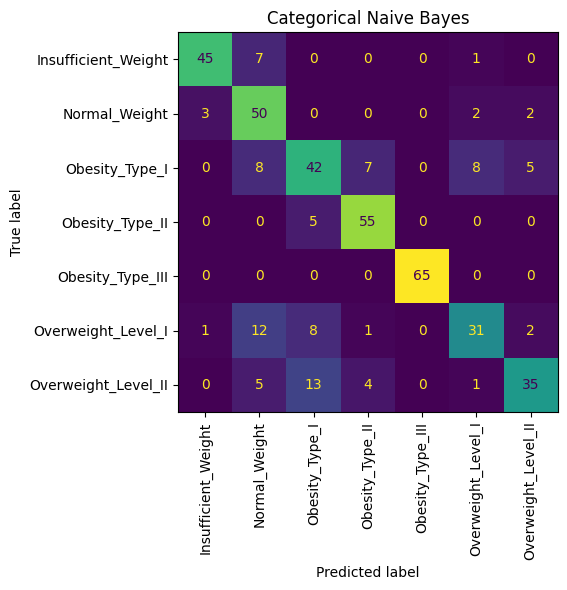

In [15]:
# Avaliar
metrics_df = pd.DataFrame([{
    "Accuracy": accuracy_score(y_test, pred_nb),
    "Precision": precision_score(
        y_test, pred_nb, average="macro", zero_division=0
    ),
    "Recall": recall_score(
        y_test, pred_nb, average="macro", zero_division=0
    ),
    "F1-score": f1_score(
        y_test, pred_nb, average="macro", zero_division=0
    )
}], index=["CategoricalNB"])

print(metrics_df.round(3))
print(classification_report(y_test, pred_nb, zero_division=0))

# Matriz de confusão
fig, ax = plt.subplots(figsize=(8, 6))
ConfusionMatrixDisplay.from_predictions(
    y_test, pred_nb,
    xticks_rotation=90,
    ax=ax,
    colorbar=False
)
ax.set_title("Categorical Naive Bayes")
plt.tight_layout()
plt.show()

In [16]:
# Nomes das classes
print(nb.classes_)

# Probabilidades prévias das classes
print(np.exp(nb.class_log_prior_))

# Probabilidades aprendidas por característica e classe
# feature_log_prob_[classe][característica]
# Os valores estão em logaritmos.
print(nb.feature_log_prob_[0][0])

['Insufficient_Weight' 'Normal_Weight' 'Obesity_Type_I' 'Obesity_Type_II'
 'Obesity_Type_III' 'Overweight_Level_I' 'Overweight_Level_II']
[0.12822049 0.13481126 0.16836429 0.1420012  0.15518274 0.13241462
 0.13900539]
[-0.77395121 -1.16956402 -1.70019228 -3.77963382 -3.77963382]
